# Rolling Statistics Method

In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Generate synthetic time-series data with injected outliers
np.random.seed(42)

# Create 200 days of data with trend + seasonality + noise
n = 200
time_index = pd.date_range(start="2024-01-01", periods=n, freq="D")
trend = np.linspace(50, 70, n)
seasonality = 10 * np.sin(np.linspace(0, 4 * np.pi, n))
noise = np.random.normal(0, 2, n)

values = trend + seasonality + noise

# Inject 5 artificial outliers
outlier_indices = [30, 80, 120, 150, 180]
values[outlier_indices] = values[outlier_indices] + np.array([25, -22, 28, -25, 24])

# Build DataFrame
df = pd.DataFrame({"value": values}, index=time_index)
df.head(20)

,value
2024-01-01,50.993428
2024-01-02,50.455030
2024-01-03,52.755979
2024-01-04,55.230684
2024-01-05,52.432833
2024-01-06,53.139419
2024-01-07,57.460294
2024-01-08,56.516168
2024-01-09,54.704727
2024-01-10,57.371882


In [4]:
# Apply rolling mean and rolling std for outlier detection
window = 14  # Use last 14 points as local context
k = 3        # Threshold multiplier (3-sigma rule)

# Calculate rolling statistics (trailing window for online detection)
df["roll_mean"] = df["value"].rolling(window=window, min_periods=1).mean()
df["roll_std"] = df["value"].rolling(window=window, min_periods=1).std()

# Build dynamic upper and lower bounds
df["upper"] = df["roll_mean"] + k * df["roll_std"]
df["lower"] = df["roll_mean"] - k * df["roll_std"]

# Calculate rolling z-score
df["roll_z"] = (df["value"] - df["roll_mean"]) / df["roll_std"]

# Flag outliers where absolute rolling z-score exceeds threshold
df["is_outlier"] = df["roll_z"].abs() > k

# Show detected outliers
print(f"Detected outliers: {df['is_outlier'].sum()}")
print(df[df["is_outlier"]][["value", "roll_mean", "roll_z"]])

Detected outliers: 5
                 value  roll_mean    roll_z
2024-01-31   86.292531  63.100719  3.371847
2024-03-21   26.171372  46.164089 -3.230300
2024-04-30  101.263159  71.253189  3.279537
2024-05-30   40.102933  65.920734 -3.280789
2024-06-29   84.022106  60.209602  3.286903


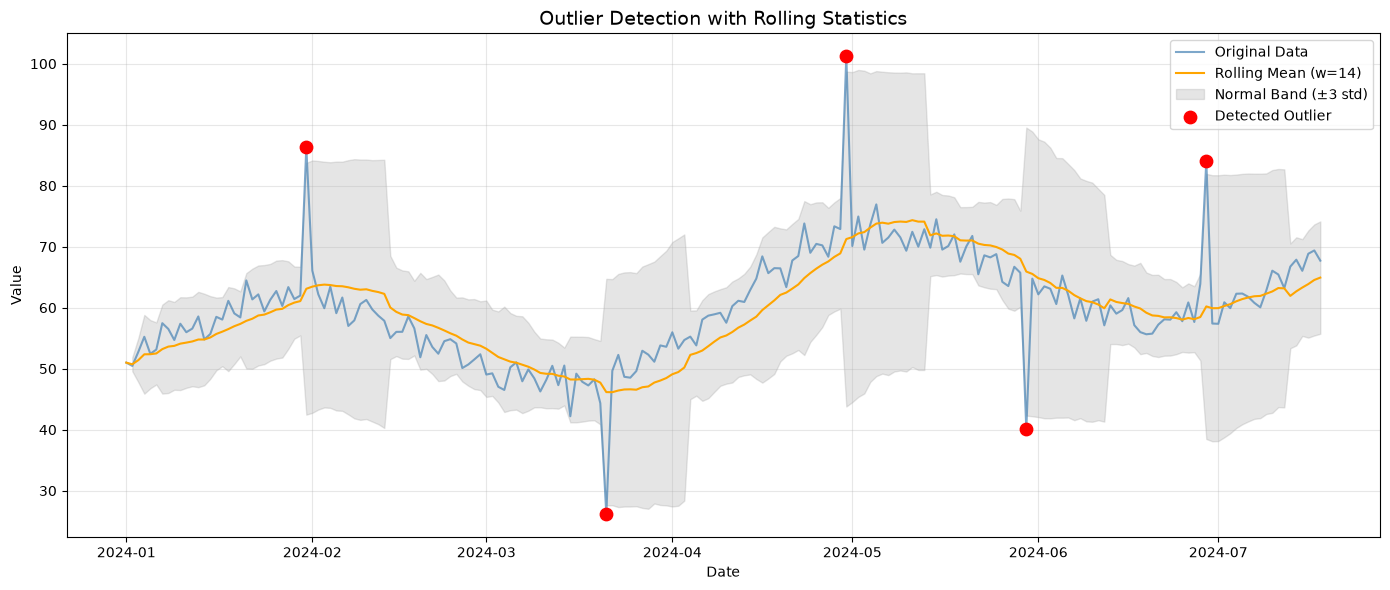

In [5]:
#  Visualize results with rolling bands and outliers
plt.figure(figsize=(14, 6))

# Plot original series and rolling mean
plt.plot(df.index, df["value"], label="Original Data", color="steelblue", alpha=0.7)
plt.plot(df.index, df["roll_mean"], label=f"Rolling Mean (w={window})", color="orange")

# Fill the normal band between upper and lower bounds
plt.fill_between(df.index, df["lower"], df["upper"], color="gray", alpha=0.2, label="Normal Band (±3 std)")

# Highlight detected outliers
outliers = df[df["is_outlier"]]
plt.scatter(outliers.index, outliers["value"], color="red", s=80, zorder=5, label="Detected Outlier")

plt.title("Outlier Detection with Rolling Statistics", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Experiment - try different window sizes and compare
for w in [7, 14, 30]:
    rm = df["value"].rolling(window=w, min_periods=1).mean()
    rs = df["value"].rolling(window=w, min_periods=1).std()
    rz = (df["value"] - rm) / rs
    count = (rz.abs() > 3).sum()
    print(f"Window={w}: detected {count} outliers")
# Question: Which window gives the most reasonable result for this data? Why?

Window=7: detected 0 outliers
Window=14: detected 5 outliers
Window=30: detected 5 outliers
